# PRUEBA DE ANÁLISIS DE PARADAS

## ANÁLISIS INICIAL
De primeras el análisis se hará sobre una parada concreta, la 5939 correspondiente a la linea 401 siendo la quinta parada de la línea. He escogido esta debido a que la considero muy básica para empezar, puesto que esa parada no tiene correspondencia con ninguna otra línea, por lo tanto los datos de ocupación o de subidas/bajadas no se verían afectados en tanto qué otros autobuses puedan pasar por esa parada, lo cual como caso base es mejor.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(495794)


#ABRIR EL CSV COMO PANDAS DATAFRAME
data_input = pd.read_csv("../data/clean_data_5939.csv", encoding="utf-8", header=0)
dataset = pd.DataFrame(data_input)

Borramos las columnas que se duplican, como EventTime, TimeSlot e IdExternal, ya que aparecen en ambas tablas mbot y tbso

In [2]:
dataset.drop(columns=["EventDate.1", "EventTime.1", "TimeSlot.1", "IdExternal.1", "TripId.1"]);

Se eliminan aquellas filas cuya ocupación sea < 0, puesto que como se dijo en el documento adjunto con la información de la base de datos, estas instancias no tienen sentido

In [3]:
dataset.shape

(9380, 25)

In [4]:
dataset = dataset[dataset["Occupation"] >=0]
dataset = dataset[dataset["Occupation"] < 80] #Fijamos 500 como valor arbitrariamente grande, puesto que se ha dado el caso que a veces hay valores extremadamente grandes

In [5]:
dataset.shape

(9299, 25)

Se han visto afectadas +- unas 80 filas, teniendo en cuenta que días únicos a día de ejecutar la consulta tenemos unos 120 días, es una media estimada de 2 mediciones erroneas cada 3 días de medición

## ESTUDIO DE LA OCUPACIÓN
### ANÁLISIS DE UN FILTRO BASICO

El objetivo de esta parte es, en base a ciertos filtros, encontrar como resultado variables aleatorias gaussianas. De primeras interpreté o pensé, que un filtro básico sería seleccionar todas las variables de un día, pero el problema de este caso es que las variables conforman una serie temporal a lo largo del día, lo cualhace que las dependencias que existen entre un valor y los antecedentes pasados sea lo suficientemente considerable como para alterar el comportamiento de los datos.

En un caso inicial vamos a tomar el valor de medidas de todoss los lunes de paso de autobús por parada alrededor de las 9 de la mañana, por probar a ver el comportamiento. Para empezar, de cada día únicamente vamos a coger un dato, el más cercano a as 9 de la mañana. Para ello, como la consulta realizada ya está ordenada según franja horaria, bastará con coger el primer dato que aparezca de cada día

In [6]:
def extract_first_value(data: pd.DataFrame):
    visited_days = []
    return_data = pd.DataFrame(columns=data.columns)
    counter = 0
    for index, row in data.iterrows():
        if row["EventDate"] not in visited_days:
            visited_days.append(row["EventDate"])
            return_data.loc[len(return_data)] = row
    return return_data



data_mondays_9am = dataset[dataset["Weekday"] == "L"]
data_mondays_9am = data_mondays_9am[data_mondays_9am["DayType"] == "LA"]
data_mondays_9am = data_mondays_9am[data_mondays_9am["TimeSlot"] == 9]

data_mondays_9am_first = extract_first_value(data_mondays_9am)
data_mondays_9am_first.drop(columns=["EventDate.1", "EventTime.1", "TimeSlot.1", "IdExternal.1", "TripId.1"])

,TripId,IdExternal,EventDate,EventTime,TimeSlot,Line,Direction,LogicVehicle,Weekday,DayType,Season,FreeDay,Stop,TemperatureMax,TemperatureMin,RainProbMin,RainProbMax,Board,DropOff,Occupation
0,20102025401358152637,68f5e04486761436bc4f1a3c,2025-10-20,09:08:17.5510000,9,401,2,3581,L,LA,I,0,5939,21,21,10,10,4,2,27
1,1108202540187525213688,6899977bc8fbb8531ea0c0be,2025-08-11,09:03:07.4130000,9,401,2,8752,L,LA,V,0,5939,37,36,0,0,0,0,6
2,27102025401357852637,68ff28ea86761436bc978444,2025-10-27,09:02:24.5690000,9,401,2,3578,L,LA,I,0,5939,15,15,0,0,0,0,25
3,061020254013582528872,68e36bbf86761436bcafd6b9,2025-10-06,09:03:01.6310000,9,401,2,3582,L,LA,I,0,5939,23,22,0,0,0,0,8
4,2508202540135895214063,68ac0c98c8fbb8531e1a0ff9,2025-08-25,09:00:36.7210000,9,401,2,3589,L,LA,V,0,5939,31,31,5,5,1,0,11
5,1509202540135815216436,68c7bce286761436bcbdce64,2025-09-15,09:11:45.7310000,9,401,2,3581,L,LA,I,0,5939,29,29,0,0,0,0,0
6,290920254013569528872,68da323086761436bc5fceac,2025-09-29,09:14:31.5430000,9,401,2,3569,L,LA,I,0,5939,23,22,10,10,0,0,12
7,2209202540135575216787,68d0f73786761436bc0e1b5e,2025-09-22,09:01:59.5950000,9,401,2,3557,L,LA,I,0,5939,18,18,0,0,1,0,30
8,070720254013576528400,686b741fe889950da18c1967,2025-07-07,09:10:15.1030000,9,401,2,3576,L,LA,M,0,5939,32,32,0,0,1,0,17
9,171120254013582529383,691ad91486761436bc42bb3e,2025-11-17,09:09:07.1090000,9,401,2,3582,L,LA,I,0,5939,12,12,25,25,5,0,24


A partir de esto vamos a realizar evaluación de la normalidad de los atributos. Para ello vamos primero a mostrar un histograma de cómo se comporta la distribución de probabilidad

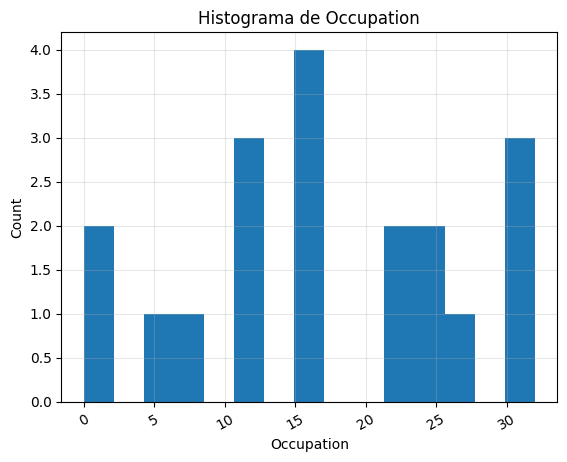

0     27
1      6
2     25
3      8
4     11
5      0
6     12
7     30
8     17
9     24
10     1
11    31
12    12
13    17
14    22
15    16
16    17
17    23
18    32
Name: Occupation, dtype: object

In [7]:
from scipy.stats import norm

#Esto se usará más adelante si se tratan las series temporales a lo largo de cada día
def project_occupation_in_daytime(data_to_project):
    plt.figure(figsize=(16,6))
    plt.plot(data_to_project["EventTime"], data_to_project["Occupation"])
    plt.xlabel('EventTime')
    plt.ylabel('Occupation')
    plt.title('Evolución de Occupation')
    plt.xticks(rotation=90)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def histogram(data_hist, variable):
    plt.hist(data_hist[variable], bins= 15)
    plt.xlabel(variable)
    plt.ylabel('Count')
    plt.title(f"Histograma de {variable}")
    plt.xticks(rotation=29)
    plt.grid(True, alpha=0.3)
    plt.show()


#Funcion para visualizar un histograma con su normal teórica ajustada(sigma1 y sigma2 == 0
def histogram_with_normal(data_to_hist, variable):
    data = np.asarray(data_to_hist[variable])
    mu = np.mean(data)
    sigma = np.std(data, ddof=0)

    # Histograma en densidad
    plt.hist(data,bins = 15, density=True, alpha=0.5, label="Datos")
    x = np.linspace(min(data), max(data), 400)
    y = norm.pdf(x, loc=mu, scale=sigma)
    plt.plot(x, y, 'r-', lw=2, label=f"N({mu:.2f}, {sigma:.2f}²)")

    plt.xlabel(variable)
    plt.ylabel('Densidad')
    plt.title(f"Histograma de {variable} + Normal ajustada")
    plt.xticks(rotation=29)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()


histogram(data_mondays_9am_first, "Occupation")
data_mondays_9am_first["Occupation"]

Aquí se ve como la variable occupation tiene una tendencia que a simple vista no se parece mucho a una campana de Gauss, aunque cierto es que con tan pocos datos es dificil a simple vista analizarlo. Para analizar mejor esta tendencia, vamos a someter a estos datos a unos experimentos que miden la simetría y la kurtosis de una variable aleatoria, con el fín de estimar su "normalidad". Los valores de skewness y kurtosis se miden calculando y estandarizando los momentos centrales de una distribución.

Estos momentos centrales se obtienen a partir de la formulación de los momentos algebráicos, denotados $ \mu_r' $ donde $r$ especifica el orden
$$
\mu_r' = E(x^r) = \sum_k k^r\, p(k)
\qquad \text{o} \qquad
\int_{-\infty}^{\infty} x^r f(x)\, dx
$$

Donde $E$ es la esperanza, $x$ y $k$ son representaciones de la variable aleatoria, tanto en su versión discreta($k$), como en su versión contínua($x$) y $r$ es el orden de magnitud del momento a calcular.


Estos momentos se calculan a partir del origen, mientras que los momentos centrales, **$\mu_r$** se calculan sobre el valor de la media, el cual se sabe como el momento algebráico **$\mu_1'$**. Estos valores **$\mu_r$** se obtienen a partir de:
$$
\mu_r = E\left[(k - E(k)\,)^{r}\right]
$$
De esta fórmula general obtenemos los momentos centrales **$\mu_1$** (Media), **$\mu_2$** (Varianza), **$\mu_3$** (skewness)[sin estandarizar] y **$\mu_4$** (kurtosis)[sin estandarizar]. Se puede obtener para una muestra de $n$ observaciones, podemos definir el cálculo de los momentos algebráicos $m_r'$ y de los momentos centrales $m_r$ como:

$$
m_r' = \frac{1} {n} \sum_{x=0}^{n}x^r
\qquad \text{y} \qquad
m_r = \frac{1} {n} \sum_{x=0}^{n}(x - m_1')^r
$$
Por lo tanto, a partir de ahora, como tratamos con muestras, $m_r$ será el equivalente muestral a $\mu_r$.

Ahora, para estandarizar una fórmula general de skewness y kurtosis, se consideran unas fórmulas genéricas a usar en vez de los momentos centrales 3 y 4, que derivan de estos, pero con la siguiente diferencia.

Se considera skewness $\gamma_1$ y kurtosis $\gamma_2$ como:
$$
\gamma_1 = \frac{m_3} {m_2^{3/2}}
\qquad \text{y} \qquad
\gamma_2 = \frac{m_4} {m_2^{2}} - 3
$$

Donde se denota que los exponentes de los denominadores de ambas fórmulas se usan para eliminar las unidades de los valores $\gamma$, puesto que los momentos centrales $m_r$ presentan grado r, y como se comparan estos con la varianza $m_2$ hay que elevar este exponente a lo necesario para que ambos numerador y denominador estén sujetos a las mismas unidades, y el resultado sea adimensional. También se destaca que de la fórmula de la kurtosis se le resta 3 al valor. Esto es debido a que es un estandar considerar kurtosis como el "sobrante" de kurtosis que tiene la distribución normal. Como la distribución gaussiana presenta kurtosis 3, se resta este valor para considerar este exceso.

Y considerando el error de cada uno de los momentos centrales, como la aproximación mediante el teorema central del límite, se obtienen las fórmulas asintóticas para el SE(Error Estandar) de skewness y Kurtosis como:
$$
SE(\gamma_1) = \sqrt{\frac{6}{n}}
\qquad \text{y} \qquad
SE(\gamma_2) = \sqrt{\frac{24}{n}}
$$

Posteriormente se calcula el Z Score tanto para $\gamma_1$ como para $\gamma_2$ como lo siguiente:

$$
Z(\gamma_1) = \frac{\gamma_1} {SE(\gamma_1)}
\qquad \text{y} \qquad
Z(\gamma_12) = \frac{\gamma_2} {SE(\gamma_2)}
$$

Como posibles resultados, según los valores de skewness y kurtosis podemos encontrar lo siguiente:


Analizando según skewness ($\gamma_1$):
- Valor $0$ → indica simetría **perfecta**
- Valor $> 0$ → la cola derecha es mayor que la izquierda
- Valor $< 0$ → la cola izquierda es mayor que la derecha

Analizando según kurtosis ($\gamma_2$)*(Asumiendo kurtosis en exceso)* :
- Valor $0$ → distribución **mesocúrtica**, similar en pico a la normal
- Valor $> 0$ → distribución **leptocúrtica**, con un pico más alto que la normal
- Valor $< 0$ → distribución **platicúrtica**, más achatada que la normal



Para traspasar todo esto a código, se ha hecho uso de las siguientes funciones

In [8]:
import math

def central_moment(x, r):
    mean = np.mean(x)
    return sum((xi - mean) ** r for xi in x) / len(x)


def kurtosis(x):
    return (central_moment(x, 4) / central_moment(x, 2) ** 2) -3

def skewness(x):
    return central_moment(x, 3) / central_moment(x, 2)**(3/2)


def general_behaviour(skew_value, kurt_value):
    return_statement = ""
    if skew_value == 0:
        if kurt_value == 0:
            return_statement += "\t-Distribución Normal perfecta"
        else:
            return_statement += "\t-Distribución Normal con simetría perfecta, pero valor de kurtosis que indica:\n"
            return_statement += "\t-Distribución leptocúrtica" if kurt_value > 0 else "\t-Distribución platicúrtica"
    else:
        if kurt_value == 0:
            return_statement += "\t-Distribución Normal con kurtosis perfecta, pero valor de skewness que indica:\n"
            return_statement += "\t-Distribución con cola más grande en el lado derecho" if skew_value > 0 else "\t-Distribución con cola más grande en el lado izquierdo"
    if skew_value > 0:
        if kurt_value > 0:
            return_statement += "\t-Cola derecha más grande que izquierda\n\t-Distribución leptocúrtica(picos más altos de lo normal)"
        else:
            return_statement += "\t-Cola derecha más grande que izquierda\n\t-Distribución platicúrtica(distribución más achatada de lo normal)"
    else:
        if kurt_value > 0:
            return_statement += "\t-Cola izquierda más grande que derecha\n\t-Distribución leptocúrtica(picos más altos de lo normal)"
        else:
            return_statement += "\t-Cola izquierda más grande que derecha\n\t-Distribución platicúrtica(distribución más achatada de lo normal)"
    return return_statement


def is_normal(variables: list):
    if len(variables) < 50: #CASO Z score 1.96
        z_crit = 1.96
    elif len(variables) < 300: #CASO Z score 3.29
        z_crit = 3.29
    else:
        z_crit = "False"

    skew = skewness(variables)
    kurt = kurtosis(variables)


    n = len(variables)
    se_skew = math.sqrt(6.0 / n)
    se_kurt = math.sqrt(24.0 / n)

    z_skew = skew / se_skew
    z_kurt = kurt / se_kurt

    if z_crit != "False":
        approx_normal = (abs(z_skew) <= z_crit) and (abs(z_kurt) <= z_crit)
    else:
        approx_normal = (abs(skew) <= 2) and (abs(kurt) + 3 <= 7) #para muestras grandes de Z > 300 no se utilizan los errores, sino valores absolutos  de medida

    print(f"-Para {n} valores, con valor skewness: {skew} y kurtosis: {kurt}, \n\n"
          f"-Con valores de SE, SE_skewness: {se_skew}, SE_kurtosis: {se_kurt}, \n\n"
          f"-Se obtienen los siguientes valores de Z; Z_skew: {z_skew} y Z_kurtosis: {z_kurt}, \n\n"
          f"-Se concluye por lo tanto que la hipótesis de que la distribución es normal es: {approx_normal}\n\n"
          f"-El comportamiento general de esta distribución es:\n{general_behaviour(skew, kurt)}")
    return None

In [9]:
is_normal(data_mondays_9am_first["Occupation"])

-Para 19 valores, con valor skewness: -0.19782242818299264 y kurtosis: -0.9334234126787733, 

-Con valores de SE, SE_skewness: 0.5619514869490163, SE_kurtosis: 1.1239029738980326, 

-Se obtienen los siguientes valores de Z; Z_skew: -0.35202759095277614 y Z_kurtosis: -0.8305195682874482, 

-Se concluye por lo tanto que la hipótesis de que la distribución es normal es: True

-El comportamiento general de esta distribución es:
	-Cola izquierda más grande que derecha
	-Distribución platicúrtica(distribución más achatada de lo normal)


En este caso se ve como el experimento ha resultado en una aceptación de la hipótesis de normalidad de los datos. Antes de revisar otros días a la misma hora para analizar el comportamiento, vamos a echarle un vistazo a esos casos más alejados de la media que se obtienen en esta distribución. Para ello, de tener una muestra con un número de población mayor, seguiríamos la regla de capturar todos los datos alejados una distancia de $2\sigma$ de la media de la distribución, y a estudiar qué hay(si hay algo) de especial o distinto en esos días. Como de primeras, al trabajar con muestras más pequeñas, vamos a realizar un experimento para identificar aquellos valores detectados como outliers, mediante el test ESD generalizado.

El test ESD Generalizado(*E*xtreme *S*tudentized *D*eviate de las siglas *ESD*) es un test propuesto por Rosner en 1983, el cual, a diferencia de otros test como el de Grubss, o el de Tietjen-Moore que necesitan saber qué numero de outliers se consideran, este test evalúa mediante hipótesis cuál es el número adecuado de outliers para una distribución, para ello recurre a lo siguiente:

El algoritmo define las siguientes hipótesis:

$H_0$: No hay outliers

$H_a$: Hay hasta $r$ outliers

Luego, se sigue un proceso iterativo, en el cual se computa la siguiente fórmula para cada iteración $i$:

$$
R_i = \frac {\max_i{\left|x_i-\bar{x}\right|}}{s}
$$
Donde $\bar{x}$ denota la media y $s$ es la desviación estándar muestral, que difiere de $m_2$(desviación estándar de la población) en que en su cálculose multiplica por $\frac {1} {n - 1}$ en vez de $\frac {1} {n}$
En cada iteración se encuentra el valor que maximiza esa $R_i$, y se almacena. En la siguiente iteración $i+1$ se recalcula esa $R_{i+1}$ sin tener en cuenta el valor anterior

Esto se repite hasta que se han computado los $r$ datos de la $H_a$

Luego, con un nivel definido de significancia $\alpha$, para cada $R_i$ con $i \in 1,2,....,i$ se calcula un valor $\lambda_i$

$$
\lambda_i = \frac {\left ( n - i \right ) t_{p, n-i-1}} {\sqrt{\left ( n- i -1 + t_{p, n-i-1}^{2} \right ) \left ( n -i +1 \right )}}
$$
Donde $t_{p,v}$ se corresponde con el cuantil p de la distribución t con v grados de libertad. En estas fórmulas, $v$ se corresponde con $n-i-1$ y p con
$$
p = 1 - \frac {\alpha} {2 \left ( n - i + 1 \right )}
$$


De todo esto obtenemos que el número de outliers es determinado según el máximo valor $i$ que cumpla que $R_i > \lambda_i$

En código

In [10]:
from math import sqrt
from scipy.stats import t as t_student


def calculate_lambda(iter_value, n_elems, significance_level: float = 0.05):
    """

    :param iter_value: the iteration i in which calculate the associate lambda
    :param significance_level:
    :param n_elems:
    :return: The lambda value for that iteration
    """
    calculate_p = 1 - (significance_level / (2*(n_elems - iter_value +1)))

    t_p_v = t_student.ppf(calculate_p, (n_elems - iter_value - 1))

    return ((n_elems - iter_value) * t_p_v)/sqrt((n_elems - iter_value - 1 + t_p_v*t_p_v)* (n_elems - iter_value + 1))



def calc_r_value(element, variables):
    """
    Function to calculate the R value of a data given the sample it belongs
    :param element: The element to calculate the R value of
    :param variables: The complete sample to evaluate mean and sample standard deviation
    :return: The r value for that element
    """


    mean = np.mean(variables)
    s = sqrt(sum((xi - mean) ** 2 for xi in variables) / (len(variables) -1))
    return abs(element - mean)/s




def extract_r_parameters(variables: list, r:int):
    """

    :param variables:
    :param r:
    :return:
    """

    #variables = np.array(variables)
    r_parameters = []
    variables_as_dict = {}

    for iteration in range(r):

        for variable in variables:
            variables_as_dict[variable] = calc_r_value(variable, variables)


        item, max_r = 0, 0
        for key,value in variables_as_dict.items():
            if value > max_r:
                max_r = value
                item = key
        r_parameters.append((item, max_r))
        #print(f"DEBUG voy a eliminar {item} con {max_r}")

        variables.remove(item)
        variables_as_dict = {}

    return r_parameters




def estimate_outliers(variables:list, outliers_hipotesis: int, significance_level: float = 0.05):
    """

    :param variables:
    :param outliers_hipotesis:
    :param significance_level:
    :return:
    """
    r_parameters = extract_r_parameters(variables, outliers_hipotesis)

    #FOR THE FORMATTED EXIT
    print(f"H_0:\tThere are No outliers")
    print(f"H_a:\tThere are up to {outliers_hipotesis} outliers in the data")
    print(f"\nSignificance level : {significance_level}")
    print(f"Critical Region: Reject H_0 if R_i > Critical value")
    print(f"\nSummary Table for EDC Test")
    print(f"-----------------------------------------------------------")
    print(f" Exact              Test                        Critical")
    print(f"Number of           Statistic                   Value, λ ")
    print(f"Outliers, i         Value, R_i                     5%")
    print(f"-----------------------------------------------------------")

    lambda_values = []
    for iteration in range(outliers_hipotesis):
        iteration_value = calculate_lambda(iteration, len(variables))
        print(f"\t{iteration + 1}\t\t\t{r_parameters[iteration][1]}\t\t\t{iteration_value}")


estimate_outliers(data_mondays_9am_first["Occupation"].tolist(), 4)


H_0:	There are No outliers
H_a:	There are up to 4 outliers in the data

Significance level : 0.05
Critical Region: Reject H_0 if R_i > Critical value

Summary Table for EDC Test
-----------------------------------------------------------
 Exact              Test                        Critical
Number of           Statistic                   Value, λ 
Outliers, i         Value, R_i                     5%
-----------------------------------------------------------
	1			1.7954486874202735			2.5856763406719616
	2			1.9340114064755367			2.5483077717433393
	3			1.6523474516094778			2.5073208525788404
	4			1.6150141076123115			2.4620328685426998


Tras la ejecución de este experimento para este dataset, se muestra como no se ha aceptado en ninguno de los casos la Hipótesis alternativa de que existian outliers. No obstante, este experimento en este caso puede estar influido por el poco número muestral que se tiene. Se dejará para experimentos con mayores muestras. Aún así, viendo el histograma:

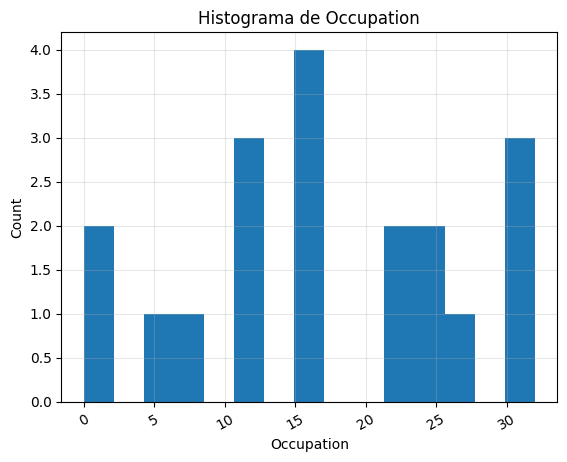

In [11]:
histogram(data_mondays_9am_first, "Occupation")

Se observaba como la ocupación en la zona máxima (>30) era "notoria" (conteo de 3 para una muestra de 19), por lo que vamos a ver si esos días tenían algo en común distinto al resto.

In [16]:
potencial_abnormal_data = data_mondays_9am_first[data_mondays_9am_first["Occupation"] >= 30]
potencial_abnormal_data

,TripId,IdExternal,EventDate,EventTime,TimeSlot,Line,Direction,LogicVehicle,Weekday,DayType,...,EventDate.1,EventTime.1,TimeSlot.1,TemperatureMax,TemperatureMin,RainProbMin,RainProbMax,Board,DropOff,Occupation
7,2209202540135575216787,68d0f73786761436bc0e1b5e,2025-09-22,09:01:59.5950000,9,401,2,3557,L,LA,...,2025-09-22,09:22:00.5350000,9,18,18,0,0,1,0,30
11,0109202540135837217569,68b548b386761436bc303951,2025-09-01,09:13:07.0760000,9,401,2,3583,L,LA,...,2025-09-01,09:25:32.3610000,9,22,22,0,0,5,0,31
18,080920254013577522214,68be86fc86761436bc75e111,2025-09-08,09:25:27.5610000,9,401,2,3577,L,LA,...,2025-09-08,09:43:02.4940000,9,27,26,10,10,6,0,32


Algo curioso de primeras que se observa en estos valores es, por ejemplo, que 2 de los Lunes, el 1 de Septiembre y el 8 de Septiembre, los coincidentes con días de mayor ocupación a las 9 de la mañana, son días en los que hubo gratuidad,(Ya que FreeDay = 1 en esas instancias. También cabe destacar que la predicción de temperatura a esa hora de la mañana del día que no presenta gratuidad es 4 y 8~9 grados menor a lo registrado en los otros días. Puesto que este día no tuvo gratuidad, la baja temperatura pudo ser motivo de la alta ocupación.


Vamos a revisar más conjuntos de días a ver si el comportamiento es parecido, por ejemplo de los martes.

In [13]:
"""
data_tuesdays_9am = dataset[dataset["Weekday"] == "M"]

data_tuesdays_9am = data_tuesdays_9am[data_tuesdays_9am["DayType"] == "LA"]

data_tuesdays_9am = data_tuesdays_9am[data_tuesdays_9am["TimeSlot"] == 9]

data_tuesdays_9am_first = extract_first_value(data_tuesdays_9am)
"""

'\ndata_tuesdays_9am = dataset[dataset["Weekday"] == "M"]\n\ndata_tuesdays_9am = data_tuesdays_9am[data_tuesdays_9am["DayType"] == "LA"]\ndata_tuesdays_9am = data_tuesdays_9am[data_tuesdays_9am["TimeSlot"] == 9]\n\ndata_tuesdays_9am_first = extract_first_value(data_tuesdays_9am)\n'

In [14]:
#histogram(data_tuesdays_9am_first, "Occupation")

In [15]:
#is_normal(data_tuesdays_9am_first["Occupation"])